# **[실습 1] Logistic Regression**

## **데이터셋 설명**

여러 스타트업들의 지출 항목별 비용과 순이익에 대한 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| index | 번호 |
| hours_studied | 공부한 시간(H) |
| passed | 시험을 통과했다면1, 아니면 0 |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/studies.csv

## **[1-1] Gradient Descent**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 저는 설정이 뭔가 안되서 추가하는 코드
from sklearn import set_config
set_config(display="text")

### **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [3]:
# code here
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/studies.csv")
df.head()

,index,hours_studied,passed
0,0,0.50,0
1,1,0.75,0
2,2,1.00,0
3,3,1.25,0
4,4,1.50,0


**Q2. 각 컬럼의 기본적인 정보를 확인하세요.**

In [4]:
# code here
df.shape

(20, 3)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          20 non-null     int64  
 1   hours_studied  20 non-null     float64
 2   passed         20 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 612.0 bytes


**Q3. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [6]:
# code here
df.describe()

,index,hours_studied,passed
count,20.00000,20.000000,20.000000
mean,9.50000,2.787500,0.500000
std,5.91608,1.507165,0.512989
min,0.00000,0.500000,0.000000
25%,4.75000,1.687500,0.000000
50%,9.50000,2.625000,0.500000
75%,14.25000,4.062500,1.000000
max,19.00000,5.500000,1.000000


### **2. 데이터 시각화하기**

**Q1. hours_studied를 독립변수로, passsed를 종속변수로 분리한다.**

In [7]:
# code here
X = df["hours_studied"] # 독립변수 (input)
y = df["passed"]        # 종속변수 (target)

**Q2. 데이터를 산점도 그래프로 시각화한다.**

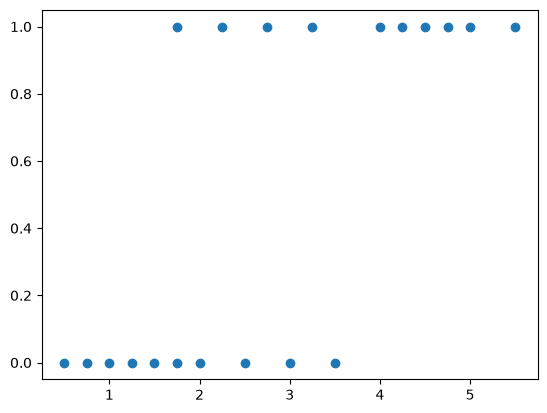

In [8]:
# code here
plt.scatter(X, y)
plt.show()

In [9]:
# 이 데이터에 line of best fit을 그려보자! 
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(np.array(X).reshape(-1,1), y)
y_pred = model.predict(np.array(X).reshape(-1,1))

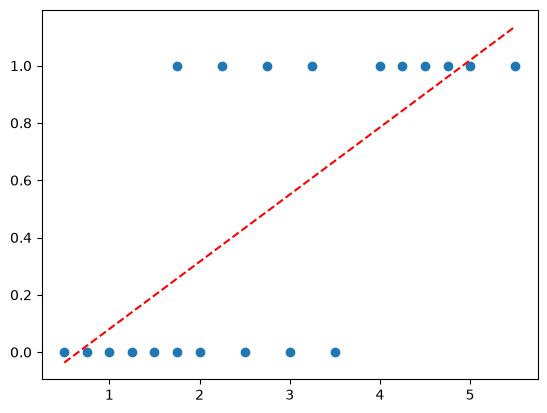

In [ ]:
plt.scatter(X, y)
plt.plot(X, y_pred, linestyle='--', color='red')
plt.show()

### **3. 모델링**

**Q1.LogisticRegression class를 생성한다.**
- 경사하강법을 구현하여 w(coefficient), b(intercept)를 구한다.

각 편미분 값은 다음과 같이 구할 수 있다.
- 𝝏𝒘 = (1/n) * np.sum((y_pred - y) * X)
- 𝛛𝒃 = (1/n) * np.sum(y_pred - y)

predict_proba(X) : X의 데이터가 1이 될 확률을 반환한다. 즉, 0.6이 나온다면, 60% 1(성공/통과) 라는 것이다.

predict(X) : predict_proba의 결과에서 0.5 이상이면 통과(1), 아니면 실패(0)로 변환하여 반환한다.

In [18]:
# from sklearn.metrics import 


class LogisticRegression:

    def __init__(self):
        self.w = None
        self.b = None
        self.history = None     # loss 기록용

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        self.w = 0.0
        self.b = 0.0
        self.history = []

        lr = 0.01       # 1. 학습률
        epochs = 100    # 2. epoch 수
        n = X.size      # 데이터의 개수만큼으로 평균 내기

        # 경사하강법
        for epoch in range(epochs):
            # 2. 예측 결과
            z = self.w * X + self.b     # 선형방정식
            y_pred = self.sigmoid(z)    # sigmoid => 0~1의 범주

            # 3. 변화량 : 미분/gradient
            dw = (1/n) * np.sum((y_pred - y) * X)
            db = (1/n) * np.sum(y_pred - y)

            # 4. update : 변화량만큼 빼주기
            self.w -= dw * lr
            self.b -= db * lr
            loss = abs(y-y_pred).mean()
            self.history.append(loss)
            
            # 5. epoch마다 loss를 한 번 출력
            if (epoch+1) % 10 == 0:
                print(f"epoch {epoch} loss : {loss}")

    def predict(self, X):
        # 각 확률에 대해서, threshold에 적합하면 1, 아니면 0
        threshold = 0.5
        return (self.predict_proba(X) > threshold).astype(int)

    def predict_proba(self, X):
        # 각 데이터에 대한 "확률"
        return self.sigmoid(self.w * X + self.b)


In [29]:
class LogisticRegression:

    def __init__(self):
        # 조정해야 하는 parameter 값들
        self.w = None #기울기
        self.b = None #절편
        self.history = None # loss 기록용

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z)) # -> proba를 할때 사용할것

    def fit(self, X, y):
        # 1. initialization : w, b를 어떤 랜덤값으로 설정을 해주시면 됩니다.
        self.w = 0.0
        self.b = 0.0 
        self.history = [] 
        # 2가지 설정
        lr = 0.1    # 1. 학습률
        epochs = 1000 # 2. epoch수
        n = X.size   # 데이터의 개수만큼으로 평균 내기 

        # 경사하강법을 시작
        # 우리가 정해준 epochs의 수만큼 변화를 주고 update를 할것이다. 
        for epoch in range(epochs): 
            # 2. 지금의 self.w, self.b를 기반으로 예측 결과를 우선 냅니다.
            # 선형방정식
            z = self.w * X + self.b
            # 이 결과를 sigmoid에 투입해서 -> 0~1의 범주로 바꿔줍니다.
            y_pred = self.sigmoid(z)

            # 3. 변화량 (미분/gradient)를 구해야 한다. 
            dw = (1/n) * np.sum((y_pred - y) * X)
            db = (1/n) * np.sum(y_pred - y)

            # 4. update를 해준다.
            # 주의 : 변화량만큼을 더해주는게 아니라, 빼줘야 합니다. 
            self.w -= dw * lr 
            self.b -= db * lr

            loss = abs(y-y_pred).mean()
            self.history.append(loss)

            # 5. epoch마다 일단 loss를 출력을 한번 해봅시다.
            if (epoch+1) % 100 == 0: # epoch이 10번 끝날때마다 로그를 출력해라.
                print(f"epoch {epoch+1} loss : {loss}")

        # 2개의 예측함수를 만들겁니다.
    def predict(self,X):
        """분류가 맞았는지 평가할 때"""
        # 각 확률에 대해서, 우리가 설정한 threshold에 적합하면, 1, 아니면 0
        threshold = 0.5 # 50%를 넘어가면, 1(통과), 아니면 0으로 분류하도록 설정
        return (self.predict_proba(X) > threshold).astype(int)

    def predict_proba(self, X): 
        """확률의 변화를 그래프로 확인할 때"""
        return self.sigmoid(self.w * X + self.b)

epoch 100 loss : 0.38614620935659516
epoch 200 loss : 0.34555261325477554
epoch 300 loss : 0.3219279841994189
epoch 400 loss : 0.3070655639176501
epoch 500 loss : 0.2970751018572336
epoch 600 loss : 0.2900088527154271
epoch 700 loss : 0.28481330532566435
epoch 800 loss : 0.28087737745785873
epoch 900 loss : 0.2778251902612365
epoch 1000 loss : 0.27541400827547463


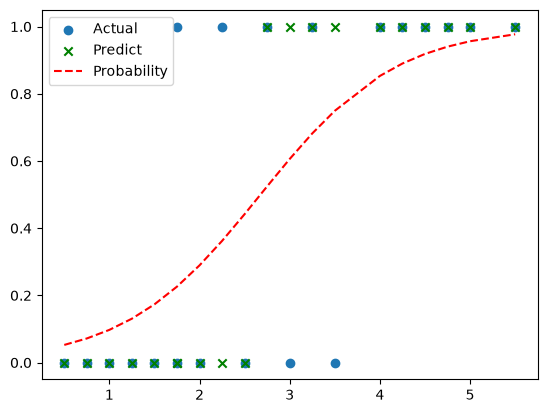

In [30]:
# 2. 모델 생성 및 학습
model = LogisticRegression()
model.fit(X, y)

# 3. 예측 확률 계산
y_proba = model.predict_proba(X)
y_pred = model.predict(X)

plt.scatter(X, y, label='Actual')
plt.scatter(X, y_pred, color='green', marker='x', label='Predict')
plt.plot(X, y_proba, '--', color='red', label='Probability')

plt.legend()
plt.show()

**Q2. 학습하기**

모델의 instance를 만들고, X, y를 사용해서 학습시킨다.

In [ ]:
from sklearn.metrics import LogisticRegression

model = LogisticRegression()
model.fit(np.array(X).reshape(-1,1), y)

# predict_proba() : 0이될 확률과 1이될 확률을 []로 반환
print(model.predict_proba(np.array(X).reshape(-1,1)))
print(model.predict(np.array(X).reshape(-1,1)))

In [31]:
# 모델을 생성하고 학습한다.
model = LogisticRegression()
model.fit(X, y)

epoch 100 loss : 0.38614620935659516
epoch 200 loss : 0.34555261325477554
epoch 300 loss : 0.3219279841994189
epoch 400 loss : 0.3070655639176501
epoch 500 loss : 0.2970751018572336
epoch 600 loss : 0.2900088527154271
epoch 700 loss : 0.28481330532566435
epoch 800 loss : 0.28087737745785873
epoch 900 loss : 0.2778251902612365
epoch 1000 loss : 0.27541400827547463


**Q3. 예측하기**

predict_proba를 사용해서 예측 결과 (확률)을 y_pred에 저장한다.

In [ ]:
# 각 데이터가 1일 예측 확률
y_pred = model.predict_proba(X)

# # 3. 예측 확률 계산
# y_proba = model.predict_proba(X)
# y_pred = model.predict(X)

### **4. 결과 시각화하기**

X, y를 활용해서 산점도 그래프를 그린다.
- X, y_pred를 활용해서 선 그래프를 그린다. 선의 색은 빨간색으로 설정한다.

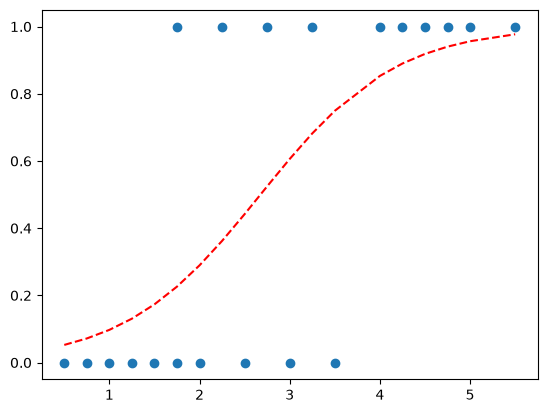

In [33]:
# code here
plt.scatter(X, y)
plt.plot(X, y_pred, linestyle='--', color='red')
plt.show()

## **[1-3] 모델 평가하기**

### **1. Confusion Matrix**

**Q1. 혼동행렬 구하기**

sklearn.metrics의 confusion_matrix를 활용하여 혼동행렬을 구하고 출력해본다.

In [ ]:
from sklearn.metrics import confusion_matrix


y_label_pred = model.predict(X)     # 평가에는 확률이 아닌 0/1 예측값을 사용
cm = confusion_matrix(y, y_label_pred)  # 혼동행렬
print(cm)

[[8 2]
 [2 8]]


**Q2. 혼돈행렬 시각화하기**

seaborn의 heatmap을 활용하여 결과를 시각화한다.

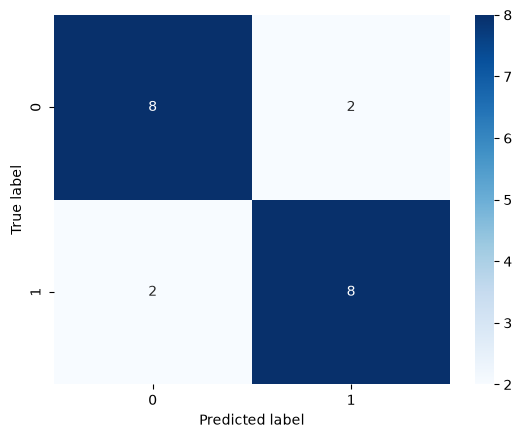

In [35]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

### **2. Classification Report**

**Q1. 정확도 출력하기**

In [36]:
from sklearn.metrics import accuracy_score

print(f"정확도: {accuracy_score(y, y_label_pred):.3f}")

정확도: 0.800


**Q2. 분류 리포트 출력하기**

In [37]:
from sklearn.metrics import classification_report

print(classification_report(y, y_label_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.80      0.80      0.80        10
           1       0.80      0.80      0.80        10

    accuracy                           0.80        20
   macro avg       0.80      0.80      0.80        20
weighted avg       0.80      0.80      0.80        20

